In [34]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, roc_curve

import warnings
warnings.filterwarnings('ignore')

churn = pd.read_csv(r"C:\Users\SuNi\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")
churn.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [35]:
churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [36]:
churn.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [37]:
churn.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [38]:
churn.duplicated().sum()

np.int64(0)

In [39]:
churn['TotalCharges'] = pd.to_numeric(churn['TotalCharges'], errors='coerce')
churn['TotalCharges'] = churn['TotalCharges'].fillna(churn['TotalCharges'].mean(), inplace=True)
churn['TotalCharges'].apply(type).value_counts()

TotalCharges
<class 'float'>    7043
Name: count, dtype: int64

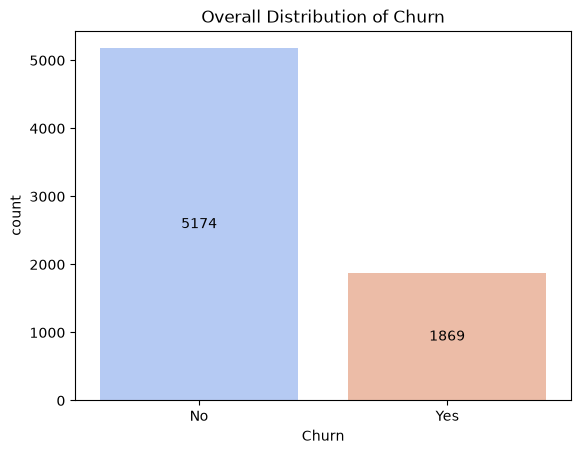

In [40]:
plt.Figure(figsize=(6,4))
ax = sns.countplot(x=churn['Churn'], palette='coolwarm')
for container in ax.containers:
    ax.bar_label(container, label_type='center')
plt.title('Overall Distribution of Churn')
plt.show()

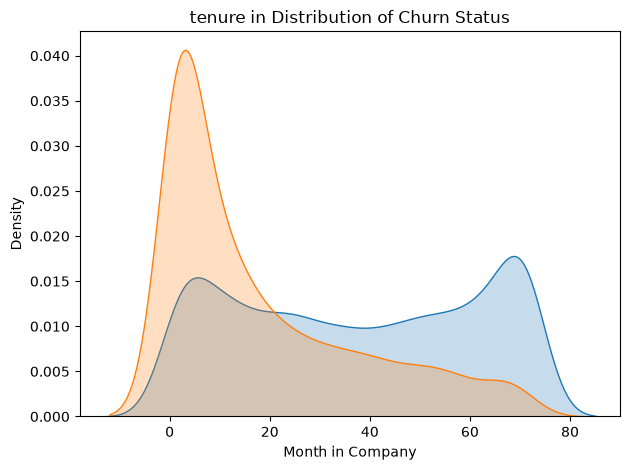

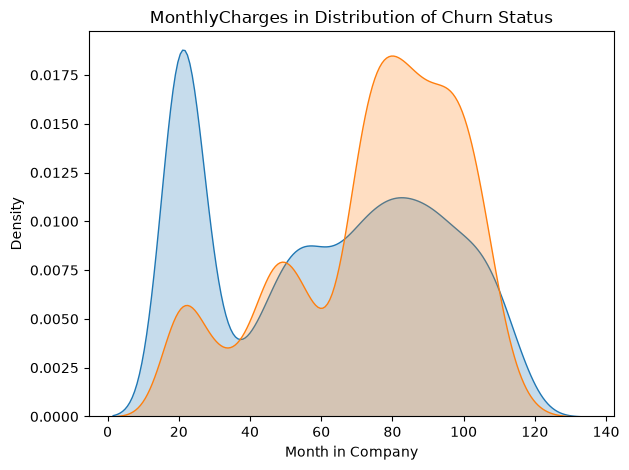

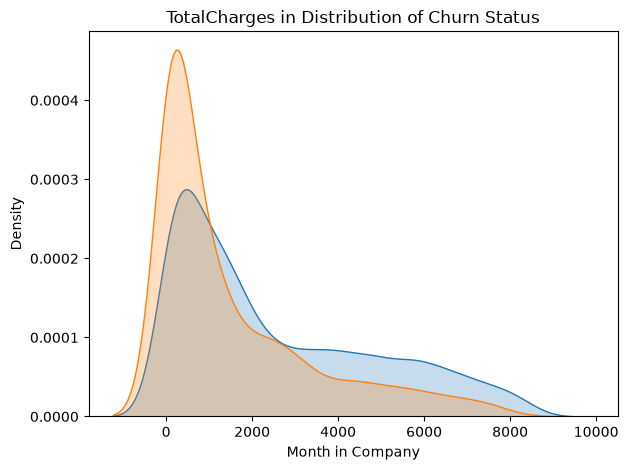

In [41]:
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    plt.Figure(figsize=(8,4))
    sns.kdeplot(churn[churn['Churn'] == 'No'][col], label='Stayed', fill=True)
    sns.kdeplot(churn[churn['Churn'] == 'Yes'][col], label='Churned', fill=True)
    plt.title(f'{col} in Distribution of Churn Status')
    plt.xlabel('Month in Company')
    plt.tight_layout()
    plt.show()

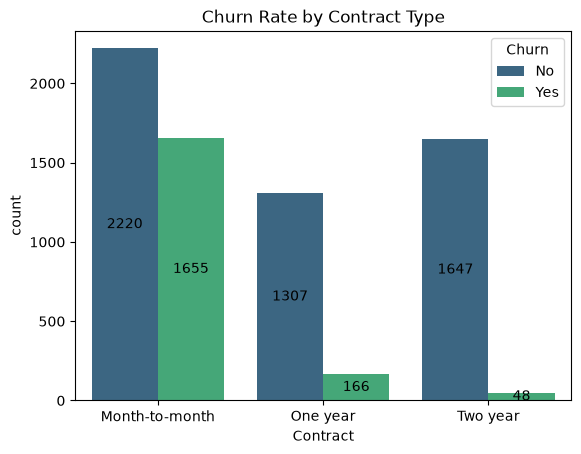

In [42]:
plt.Figure(figsize=(6,4))
ax = sns.countplot(x=churn['Contract'], hue=churn['Churn'], palette='viridis')
for container in ax.containers:
    ax.bar_label(container, label_type='center')
plt.title('Churn Rate by Contract Type')
plt.show()

In [43]:
word_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 
'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 
'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

for col in word_cols:
    churn[col] = churn[col].fillna(churn[col].mode()[0])

num_cols = churn.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    churn[col] = churn[col].fillna(churn[col].mean())

encoders = {}
for col in word_cols:
    encoders = LabelEncoder()
    churn[col] = encoders.fit_transform(churn[col]).astype(str)

churn.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,1,0,0,...,0,0,0,0,0,1,2,29.85,29.85,0
1,5575-GNVDE,1,0,0,0,34,1,0,0,2,...,2,0,0,0,1,0,3,56.95,1889.50,0
2,3668-QPYBK,1,0,0,0,2,1,0,0,2,...,0,0,0,0,0,1,3,53.85,108.15,1
3,7795-CFOCW,1,0,0,0,45,0,1,0,2,...,2,2,0,0,1,0,0,42.30,1840.75,0
4,9237-HQITU,0,0,0,0,2,1,0,1,0,...,0,0,0,0,0,1,2,70.70,151.65,1


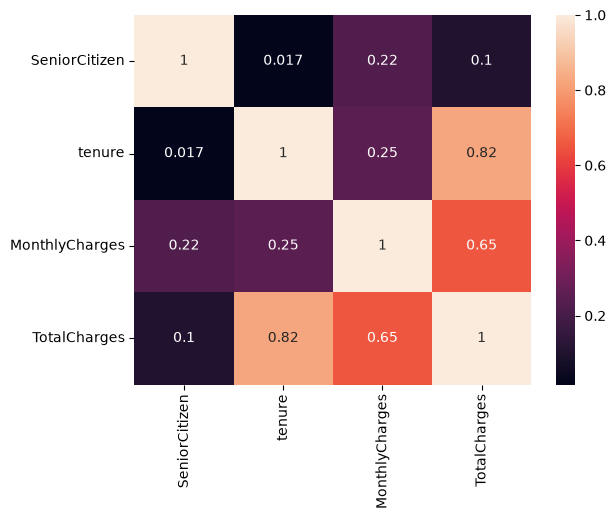

In [44]:
corr = abs(churn.corr(numeric_only=True))
sns.heatmap(corr, annot=True)
plt.show()

In [45]:
X = churn.drop(['customerID', 'Churn'], axis=1)
y = churn['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [46]:
models = {
    'Logistic Regression': LogisticRegression(),
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier()
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:,1]
    rows.append({'model': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'ROC Score': roc_auc_score(y_test, pred)
                 })

results = pd.DataFrame(rows).set_index('model').round(4)
print("\n", results)


                      Accuracy  ROC Score
model                                   
Logistic Regression    0.8162     0.7412
Random Forest          0.7935     0.6897
Decision Tree          0.7225     0.6500


In [47]:
best_name = results['ROC Score'].idxmax()
best_model = models[best_name]
best_pred = best_model.predict(X_test)
print("\nBest Model:", best_name)
print(classification_report(y_test, best_pred, target_names=['stayed', 'churned']))


Best Model: Logistic Regression
              precision    recall  f1-score   support

      stayed       0.86      0.90      0.88      1036
     churned       0.68      0.58      0.63       373

    accuracy                           0.82      1409
   macro avg       0.77      0.74      0.75      1409
weighted avg       0.81      0.82      0.81      1409



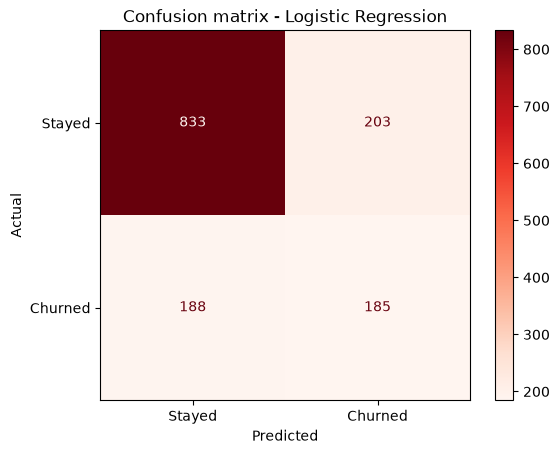

In [48]:
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=['Stayed', 'Churned']).plot(cmap='Reds')
plt.title("Confusion matrix - " + best_name)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

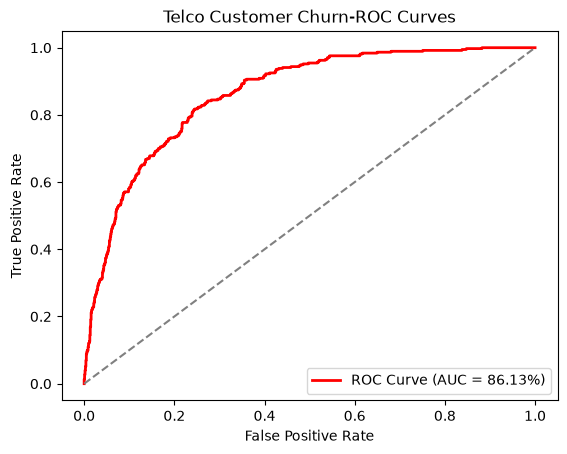

In [49]:
y_test = y_test.astype(int)
best_pred_proba = best_model.predict_proba(X_test)[:,1]

fpr, tpr,_ = roc_curve(y_test, best_pred_proba)
auc_score = roc_auc_score(y_test, best_pred_proba)

plt.Figure(figsize=(10, 5))
plt.plot(fpr, tpr, color='red', lw=2, label=f'ROC Curve (AUC = {auc_score*100:.2f}%)')
plt.plot([0,1], [0,1], color='grey', linestyle='--')
plt.title('Telco Customer Churn-ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()